# MADT 7202 Mid-Term · Swiftie Bridge Artists
**Decision:** แบรนด์ที่อยากเจาะกลุ่มแฟน Taylor Swift ควรเลือกศิลปินคนไหนมาทำ campaign — คนที่ *ใกล้ Swift* และ *เป็นสะพานไปฐานแฟนกลุ่มอื่น*

**Data:** Last.fm API (`artist.getSimilar`, `artist.getTopTags`) · Data courtesy of Last.fm (https://www.last.fm)

วิธีใช้: ใส่ `API_KEY` ในเซลล์ถัดไป แล้ว **Runtime → Run all** (ใช้เวลาดึงข้อมูลราว 3–6 นาที)

In [1]:
# ==== CONFIG ====
API_KEY = "PASTE_YOUR_LASTFM_API_KEY_HERE"
SEED = "Taylor Swift"
LIMIT_L1 = 30        # similar artists of the seed (layer 1)
LIMIT_L2 = 30        # similar artists of each layer-1 artist (layer 2)
CUTOFF = 0.30        # main pruning cutoff on similarity (match)
SWEEP = [0.20, 0.30, 0.40]
MIN_DEGREE = 2
TOP_N = 5

# Tags that connect to everything and carry no genre meaning (generic-term exclusion)
GENERIC_TAGS = {"seen live","female vocalists","female vocalist","male vocalists","favorites",
    "favourite","favorite","american","british","canadian","australian","singer-songwriter",
    "all","love","beautiful","awesome","00s","10s","2010s","2020s","90s","under 2000 listeners",
    "spotify","my favorite","favourites","usa","english","female","male","pop","my top songs","swedish"}

In [2]:
import requests, json, time, os, datetime
import pandas as pd, numpy as np, networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

BASE = "https://ws.audioscrobbler.com/2.0/"
CACHE = "lastfm_cache"; os.makedirs(CACHE, exist_ok=True)

def call(method, artist, limit=None):
    key = f"{method}__{artist}__{limit}".replace("/", "_")
    path = os.path.join(CACHE, key[:150] + ".json")
    if os.path.exists(path):
        return json.load(open(path))
    params = {"method": method, "artist": artist, "api_key": API_KEY, "format": "json", "autocorrect": 1}
    if limit: params["limit"] = limit
    for attempt in range(3):
        r = requests.get(BASE, params=params, timeout=20)
        if r.status_code == 200:
            data = r.json(); json.dump(data, open(path, "w")); time.sleep(0.25)  # stay well under rate limit
            return data
        time.sleep(2 * (attempt + 1))
    return {}

def similar(artist, limit):
    d = call("artist.getsimilar", artist, limit)
    return [(a["name"], float(a["match"])) for a in d.get("similarartists", {}).get("artist", [])]

def top_tags(artist):
    d = call("artist.gettoptags", artist)
    return [(t["name"].lower().strip(), int(t["count"])) for t in d.get("toptags", {}).get("tag", [])]

## 1. เก็บข้อมูล (2-hop crawl จาก seed)

In [3]:
if os.path.exists("raw_similar_edges.csv"):          # re-run from the saved pull (no API calls)
    raw = pd.read_csv("raw_similar_edges.csv"); FETCHED_AT = raw.fetched_at.iloc[0]
    l1 = list(raw[raw.layer == 1][["target", "match"]].itertuples(index=False, name=None))
else:
  FETCHED_AT = datetime.datetime.now().isoformat(timespec="minutes")
  rows = []
  l1 = similar(SEED, LIMIT_L1)
  for name, m in l1:
      rows.append({"source": SEED, "target": name, "match": m, "layer": 1})
  for i, (name, _) in enumerate(l1, 1):
      for t, m in similar(name, LIMIT_L2):
          rows.append({"source": name, "target": t, "match": m, "layer": 2})
      print(f"\r{i}/{len(l1)} {name}          ", end="")
  raw = pd.DataFrame(rows); raw["fetched_at"] = FETCHED_AT
  raw.to_csv("raw_similar_edges.csv", index=False)
L1 = {n for n, _ in l1}
swift_sim = dict(l1)
print(f"\nRecords: {len(raw)} | layer-1 artists: {len(L1)} | unique artists: {pd.unique(raw[['source','target']].values.ravel()).size}")


Records: 929 | layer-1 artists: 30 | unique artists: 337


## 2. สร้าง graph
- Node = ศิลปิน · Edge = Last.fm ระบุว่ามีคนฟังซ้อนกัน · Weight = similarity (ถ้า A→B ≠ B→A ใช้ max)
- **ลบ seed (Taylor Swift) ออกก่อน rank** · ตัด edge < cutoff · ตัด node ที่ degree < 2 · เก็บ largest component

In [4]:
def build_graph(raw, cutoff, min_degree=MIN_DEGREE):
    G = nx.Graph()
    for r in raw.itertuples():
        a, b = r.source, r.target
        if a == b: continue
        w = max(r.match, G[a][b]["weight"]) if G.has_edge(a, b) else r.match
        G.add_edge(a, b, weight=w)
    G.remove_nodes_from([n for n in list(G) if n.lower() == SEED.lower()])   # seed exclusion
    G.remove_edges_from([(u, v) for u, v, w in G.edges(data="weight") if w < cutoff])
    while True:
        low = [n for n, d in G.degree() if d < min_degree]
        if not low: break
        G.remove_nodes_from(low)
    if G.number_of_nodes():
        G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    for u, v, w in G.edges(data="weight"):
        G[u][v]["dist"] = 1 - w + 1e-6   # strong similarity = short path
    return G

def metrics(G):
    btw = nx.betweenness_centrality(G, weight="dist", normalized=True)
    df = pd.DataFrame({"artist": list(G)})
    df["betweenness"] = df.artist.map(btw)
    df["degree"] = df.artist.map(dict(G.degree()))
    df["swift_similarity"] = df.artist.map(swift_sim).fillna(0.0)
    df["in_layer1"] = df.artist.isin(L1)
    return df.sort_values("betweenness", ascending=False).reset_index(drop=True)

G = build_graph(raw, CUTOFF)
M = metrics(G)
print(f"cutoff={CUTOFF}: nodes={G.number_of_nodes()} edges={G.number_of_edges()}")

cutoff=0.3: nodes=158 edges=520


## 3. Genre tags (ใช้ลงสีและเป็น construction ทางเลือก) — ตัด generic tags ออก

In [5]:
tags = {}
if os.path.exists("artist_tags.csv"):   # saved pull: raw top tags kept before generic filtering where available
    T = pd.read_csv("artist_tags.csv")
    for a, grp in T.groupby("artist", sort=False):
        tags[a] = [(t, c) for t, c in zip(grp.tag, grp["count"]) if t not in GENERIC_TAGS][:10]
    for a in G.nodes(): tags.setdefault(a, [])   # artists with no usable tags in the saved pull
else:
    for i, a in enumerate(G.nodes(), 1):
        tags[a] = [(t, c) for t, c in top_tags(a) if t not in GENERIC_TAGS][:10]
        print(f"\r{i}/{G.number_of_nodes()}", end="")
M["primary_tag"] = M.artist.map(lambda a: tags[a][0][0] if tags.get(a) else "unknown")
pd.DataFrame([{"artist": a, "tag": t, "count": c} for a, ts in tags.items() for t, c in ts]).to_csv("artist_tags.csv", index=False)

# Group the long tail of tags into a few colour groups for the figure
top_groups = M.primary_tag.value_counts().head(6).index.tolist()
M["genre_group"] = M.primary_tag.where(M.primary_tag.isin(top_groups), "other")
print("\n", M.genre_group.value_counts())


 genre_group
other        55
indie pop    29
country      24
rnb          17
dance        12
indie        11
pop rock     10
Name: count, dtype: int64


## 4. Findings: ใครใกล้ Swift และเป็นสะพาน
Candidate = ศิลปินชั้นที่ 1 (แฟนซ้อนกับ Swift โดยตรง) จัดอันดับด้วย betweenness

In [6]:
cand = M[M.in_layer1].copy()
cand["sim_rank"] = cand.swift_similarity.rank(ascending=False).astype(int)
cand["btw_rank"] = cand.betweenness.rank(ascending=False).astype(int)
# neighbours outside the Swift layer-1 circle = reach into new audiences
cand["new_reach"] = cand.artist.map(lambda a: sum(1 for n in G[a] if n not in L1))
cand["neighbour_genres"] = cand.artist.map(lambda a: M.set_index("artist").loc[list(G[a]), "genre_group"].nunique())
cols = ["artist","swift_similarity","sim_rank","betweenness","btw_rank","degree","new_reach","neighbour_genres","primary_tag"]
shortlist = cand.sort_values("betweenness", ascending=False)[cols]
shortlist.to_csv("shortlist.csv", index=False)
display(shortlist.head(10).round(3))

top_sim = cand.sort_values("swift_similarity", ascending=False).iloc[0]
top_btw = shortlist.iloc[0]
print(f"Most similar to Swift: {top_sim.artist} (sim {top_sim.swift_similarity:.2f}, betweenness {top_sim.betweenness:.3f}, new_reach {top_sim.new_reach})")
print(f"Best bridge:          {top_btw.artist} (sim {top_btw.swift_similarity:.2f}, betweenness {top_btw.betweenness:.3f}, new_reach {top_btw.new_reach})")
rho, p = spearmanr(cand.swift_similarity, cand.betweenness)
print(f"Spearman(similarity, betweenness) among candidates = {rho:.2f} (p={p:.3f})  -> low rho = a ranked list by similarity would pick different artists")

,artist,swift_similarity,sim_rank,betweenness,btw_rank,degree,new_reach,neighbour_genres,primary_tag
0,Gracie Abrams,0.909,2,0.521,1,25,13,5,indie pop
1,Maisie Peters,0.473,4,0.320,2,25,17,6,folk
2,Olivia Rodrigo,0.853,3,0.305,3,25,10,6,pop rock
3,Kelsea Ballerini,0.460,5,0.247,4,19,16,2,country
4,Halsey,0.293,19,0.217,5,28,16,5,indie pop
5,Troye Sivan,0.265,26,0.213,6,26,15,5,indie pop
6,Lorde,0.416,7,0.175,7,26,17,4,indie pop
7,Conan Gray,0.377,12,0.173,8,19,10,5,indie pop
8,Katy Perry,0.285,22,0.170,9,28,21,5,pop rock
9,Chappell Roan,0.443,6,0.147,10,26,13,5,indie pop


Most similar to Swift: Sabrina Carpenter (sim 1.00, betweenness 0.124, new_reach 11)
Best bridge:          Gracie Abrams (sim 0.91, betweenness 0.521, new_reach 13)
Spearman(similarity, betweenness) among candidates = 0.52 (p=0.003)  -> low rho = a ranked list by similarity would pick different artists


## 5. Robustness check 1 — cutoff sweep

In [7]:
sweep_rows, tops = [], {}
for c in SWEEP:
    Gc = build_graph(raw, c); Mc = metrics(Gc)
    t = Mc[Mc.in_layer1].head(TOP_N).artist.tolist(); tops[c] = t
    sweep_rows.append({"cutoff": c, "nodes": Gc.number_of_nodes(), "edges": Gc.number_of_edges(),
                       f"top{TOP_N}_bridges": ", ".join(t)})
sweep = pd.DataFrame(sweep_rows)
base = set(tops[CUTOFF])
sweep[f"overlap_with_{CUTOFF}"] = [f"{len(base & set(tops[c]))}/{TOP_N}" for c in SWEEP]
sweep["#1_bridge"] = [tops[c][0] if tops[c] else "-" for c in SWEEP]
sweep.to_csv("robustness_cutoff.csv", index=False)
display(sweep)

,cutoff,nodes,edges,top5_bridges,overlap_with_0.3,#1_bridge
0,0.2,174,577,"Gracie Abrams, Olivia Rodrigo, Maisie Peters, ...",5/5,Gracie Abrams
1,0.3,158,520,"Gracie Abrams, Maisie Peters, Olivia Rodrigo, ...",5/5,Gracie Abrams
2,0.4,114,354,"Gracie Abrams, Olivia Rodrigo, Halsey, Troye S...",3/5,Gracie Abrams


## 6. Robustness check 2 — construction ทางเลือก: shared-tag Jaccard แทน similarity score
Edge = Jaccard ของ genre tags (ไม่ใช้พฤติกรรมการฟัง) → bridge ยังเป็นคนเดิมไหม?

In [8]:
def tag_graph(nodes, thr=0.25):
    S = {a: {t for t, _ in tags.get(a, [])} for a in nodes}
    H = nx.Graph(); H.add_nodes_from(nodes)
    nl = list(nodes)
    for i in range(len(nl)):
        for j in range(i + 1, len(nl)):
            a, b = S[nl[i]], S[nl[j]]
            if a and b:
                jac = len(a & b) / len(a | b)
                if jac >= thr: H.add_edge(nl[i], nl[j], weight=jac, dist=1 - jac + 1e-6)
    return H

H = tag_graph(list(G.nodes()))
bt = nx.betweenness_centrality(H, weight="dist", normalized=True)
alt_top = [a for a, _ in sorted(bt.items(), key=lambda x: -x[1]) if a in L1][:TOP_N]
print(f"Tag-Jaccard graph: nodes={H.number_of_nodes()} edges={H.number_of_edges()}")
print(f"Top{TOP_N} bridges (similarity graph): {tops[CUTOFF]}")
print(f"Top{TOP_N} bridges (tag graph):        {alt_top}")
print(f"Overlap: {len(set(alt_top) & base)}/{TOP_N}")

Tag-Jaccard graph: nodes=158 edges=906
Top5 bridges (similarity graph): ['Gracie Abrams', 'Maisie Peters', 'Olivia Rodrigo', 'Kelsea Ballerini', 'Halsey']
Top5 bridges (tag graph):        ['Halsey', 'Kelsea Ballerini', 'Selena Gomez', 'Katy Perry', 'Madison Beer']
Overlap: 2/5


## 7. Figures

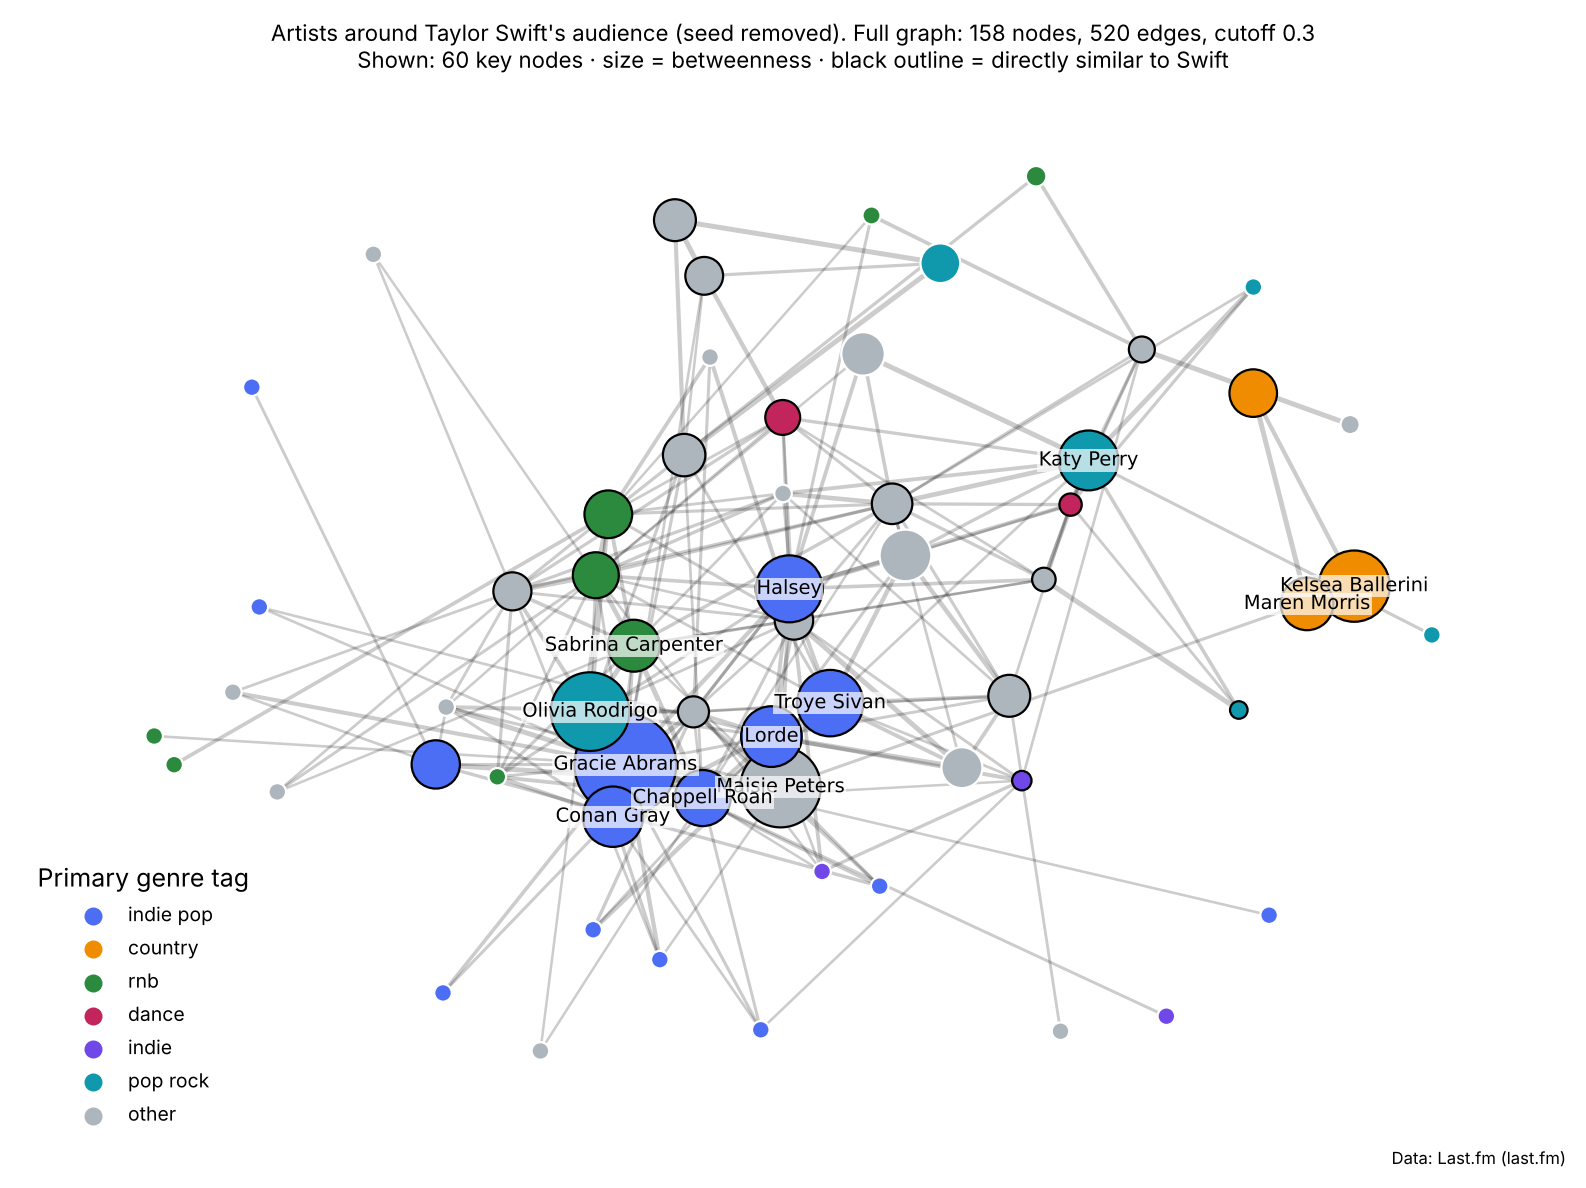

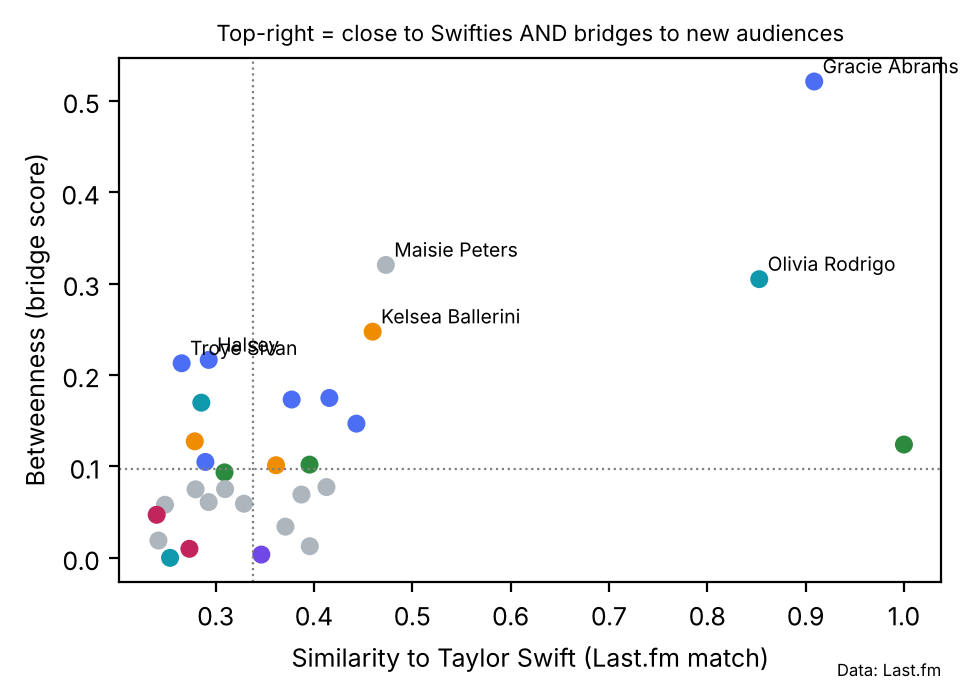

In [9]:
plt.rcParams.update({"font.size": 9})
palette = ["#4C6EF5","#F08C00","#2B8A3E","#C2255C","#7048E8","#1098AD","#ADB5BD"]
groups = [g for g in M.genre_group.value_counts().index if g != "other"] + ["other"]
cmap = {g: palette[i % len(palette)] for i, g in enumerate(groups)}
attr = M.set_index("artist")

# Figure shows the most important ~60 nodes (all layer-1 + top bridges); metrics are computed on the full graph
FIG_MAX_NODES = 60
keep = [a for a in M.artist if a in L1]
keep += [a for a in M.artist if a not in keep][: max(0, FIG_MAX_NODES - len(keep))]
F = G.subgraph(keep).copy()
F.remove_edges_from([(u, v) for u, v, w in F.edges(data="weight") if w < CUTOFF + 0.1])  # lighter edges only for drawing
F.remove_nodes_from([n for n, d in F.degree() if d == 0])

fig, ax = plt.subplots(figsize=(8, 6), dpi=200)
pos = nx.spring_layout(F, weight="weight", seed=7, k=0.6)
nx.draw_networkx_edges(F, pos, ax=ax, alpha=0.2, width=[0.3 + 1.5 * F[u][v]["weight"] for u, v in F.edges()])
sizes = [40 + 2500 * attr.loc[n, "betweenness"] for n in F]
nx.draw_networkx_nodes(F, pos, ax=ax, node_size=sizes, node_color=[cmap[attr.loc[n, "genre_group"]] for n in F],
                       edgecolors=["black" if n in L1 else "white" for n in F], linewidths=0.8)
label_nodes = [a for a in M.artist if a in F][:12]
nx.draw_networkx_labels(F, pos, labels={n: n for n in label_nodes}, font_size=7, ax=ax,
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.5))
for g in groups: ax.scatter([], [], c=cmap[g], label=g, s=30)
ax.legend(title="Primary genre tag", loc="lower left", fontsize=7, frameon=False)
ax.set_title(f"Artists around Taylor Swift's audience (seed removed). Full graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, cutoff {CUTOFF}\n"
             f"Shown: {F.number_of_nodes()} key nodes · size = betweenness · black outline = directly similar to Swift", fontsize=8)
ax.text(1, -0.02, "Data: Last.fm (last.fm)", transform=ax.transAxes, ha="right", fontsize=6)
ax.axis("off"); plt.tight_layout(); plt.savefig("fig_network.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(5, 3.6), dpi=200)
ax.scatter(cand.swift_similarity, cand.betweenness, c=[cmap[g] for g in cand.genre_group], s=30)
for r in cand.sort_values("betweenness", ascending=False).head(6).itertuples():
    ax.annotate(r.artist, (r.swift_similarity, r.betweenness), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axvline(cand.swift_similarity.median(), ls=":", c="grey", lw=0.8); ax.axhline(cand.betweenness.median(), ls=":", c="grey", lw=0.8)
ax.set_xlabel("Similarity to Taylor Swift (Last.fm match)"); ax.set_ylabel("Betweenness (bridge score)")
ax.set_title("Top-right = close to Swifties AND bridges to new audiences", fontsize=8)
ax.text(1, -0.18, "Data: Last.fm", transform=ax.transAxes, ha="right", fontsize=6)
plt.tight_layout(); plt.savefig("fig_scatter.png", bbox_inches="tight"); plt.show()

## 6b. Robustness check 3 — 12 construction configurations
cutoff {0.2, 0.3, 0.4} × symmetrise {max, mean of A→B / B→A} × betweenness {weighted by 1−similarity, unweighted}. คำถาม: bridge อันดับต้นยังเป็นคนเดิมไหม

In [10]:
def build_graph_cfg(raw, cutoff, sym="max"):
    G = nx.Graph()
    for r in raw.itertuples():
        a, b = r.source, r.target
        if a == b: continue
        if G.has_edge(a, b): G[a][b]["ws"].append(r.match)
        else: G.add_edge(a, b, ws=[r.match])
    for u, v, d in G.edges(data=True):
        d["weight"] = max(d["ws"]) if sym == "max" else float(np.mean(d["ws"]))
    G.remove_nodes_from([n for n in list(G) if n.lower() == SEED.lower()])
    G.remove_edges_from([(u, v) for u, v, w in G.edges(data="weight") if w < cutoff])
    while (low := [n for n, d in G.degree() if d < MIN_DEGREE]): G.remove_nodes_from(low)
    G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    for u, v, w in G.edges(data="weight"): G[u][v]["dist"] = 1 - w + 1e-6
    return G

cand_list = [n for n, _ in l1]
ranks, cfg_rows = {}, []
for c in SWEEP:
    for sym in ["max", "mean"]:
        Gc = build_graph_cfg(raw, c, sym)
        for wt in ["dist", None]:
            b = nx.betweenness_centrality(Gc, weight=wt, normalized=True)
            key = f"cut{c}|{sym}|{'weighted' if wt else 'unweighted'}"
            ranks[key] = pd.Series({a: b.get(a, 0.0) for a in cand_list}).rank(ascending=False, method="min")
            top = ranks[key].sort_values().index[:3].tolist()
            cfg_rows.append({"config": key, "nodes": Gc.number_of_nodes(), "edges": Gc.number_of_edges(), "top3": ", ".join(top)})
R = pd.DataFrame(ranks)
N_CFG = R.shape[1]
stab = pd.DataFrame({
    "swift_similarity": pd.Series(swift_sim),
    "sim_rank": pd.Series(swift_sim).rank(ascending=False, method="min").astype(int),
    "mean_bridge_rank": R.mean(axis=1),
    "top5_in": (R <= 5).sum(axis=1),
    "top3_in": (R <= 3).sum(axis=1),
    "rank1_in": (R == 1).sum(axis=1),
    "best_rank": R.min(axis=1).astype(int),
    "worst_rank": R.max(axis=1).astype(int),
}).sort_values("mean_bridge_rank")
stab.index.name = "artist"
stab.to_csv("robustness_12configs.csv")
pd.DataFrame(cfg_rows).to_csv("robustness_12configs_top3.csv", index=False)
display(pd.DataFrame(cfg_rows))
display(stab.head(10).round(2))
ROBUST = stab.index[0]
MOST_SIM = stab.sort_values("sim_rank").index[0]
print(f"Most robust bridge: {ROBUST}  |  Most similar to Swift: {MOST_SIM}")

,config,nodes,edges,top3
0,cut0.2|max|weighted,174,577,"Gracie Abrams, Olivia Rodrigo, Maisie Peters"
1,cut0.2|max|unweighted,174,577,"Miley Cyrus, Maisie Peters, Kacey Musgraves"
2,cut0.2|mean|weighted,174,577,"Halsey, Maisie Peters, Gracie Abrams"
3,cut0.2|mean|unweighted,174,577,"Miley Cyrus, Maisie Peters, Kacey Musgraves"
4,cut0.3|max|weighted,158,520,"Gracie Abrams, Maisie Peters, Olivia Rodrigo"
5,cut0.3|max|unweighted,158,520,"Maisie Peters, Kacey Musgraves, Kelsea Ballerini"
6,cut0.3|mean|weighted,158,516,"Halsey, Maisie Peters, Gracie Abrams"
7,cut0.3|mean|unweighted,158,516,"Maisie Peters, Kacey Musgraves, Kelsea Ballerini"
8,cut0.4|max|weighted,114,354,"Gracie Abrams, Olivia Rodrigo, Halsey"
9,cut0.4|max|unweighted,114,354,"Troye Sivan, Dua Lipa, Carly Rae Jepsen"


,swift_similarity,sim_rank,mean_bridge_rank,top5_in,top3_in,rank1_in,best_rank,worst_rank
artist,,,,,,,,
Maisie Peters,0.47,4,2.67,12,8,2,1,5
Halsey,0.29,19,4.67,8,5,3,1,10
Kelsea Ballerini,0.46,5,5.33,8,2,0,3,11
Gracie Abrams,0.91,2,5.42,5,5,3,1,9
Troye Sivan,0.27,26,6.50,4,3,1,1,13
Olivia Rodrigo,0.85,3,8.08,7,3,0,2,26
Katy Perry,0.29,22,8.75,4,1,0,3,16
Lorde,0.42,7,9.92,2,0,0,5,16
Carly Rae Jepsen,0.31,17,10.67,1,1,0,3,21


Most robust bridge: Maisie Peters  |  Most similar to Swift: Sabrina Carpenter


## 6c. Construction ทางเลือก (tag Jaccard) — top-5 bridges

In [11]:
H = tag_graph(list(G.nodes()))
bt = nx.betweenness_centrality(H, weight="dist", normalized=True)
tag_rank = pd.Series({a: bt.get(a, 0.0) for a in cand_list}).rank(ascending=False, method="min")
alt_top = tag_rank.sort_values().index[:TOP_N].tolist()
print("Tag-Jaccard top5 bridges:", alt_top)
print(f"{ROBUST} rank in tag graph: {int(tag_rank[ROBUST])} | {MOST_SIM}: {int(tag_rank[MOST_SIM])}")
stab["tag_graph_rank"] = tag_rank.astype(int)
stab.to_csv("robustness_12configs.csv")

Tag-Jaccard top5 bridges: ['Halsey', 'Kelsea Ballerini', 'Selena Gomez', 'Katy Perry', 'Madison Beer']
Maisie Peters rank in tag graph: 19 | Sabrina Carpenter: 19


## 7b. Full-graph view — the 30 artists directly similar to Swift (seed removed)
Node size = mean bridge rank across 12 configs (bigger = more robust bridge); number = neighbours outside the Swift circle; grey dots = outside artists

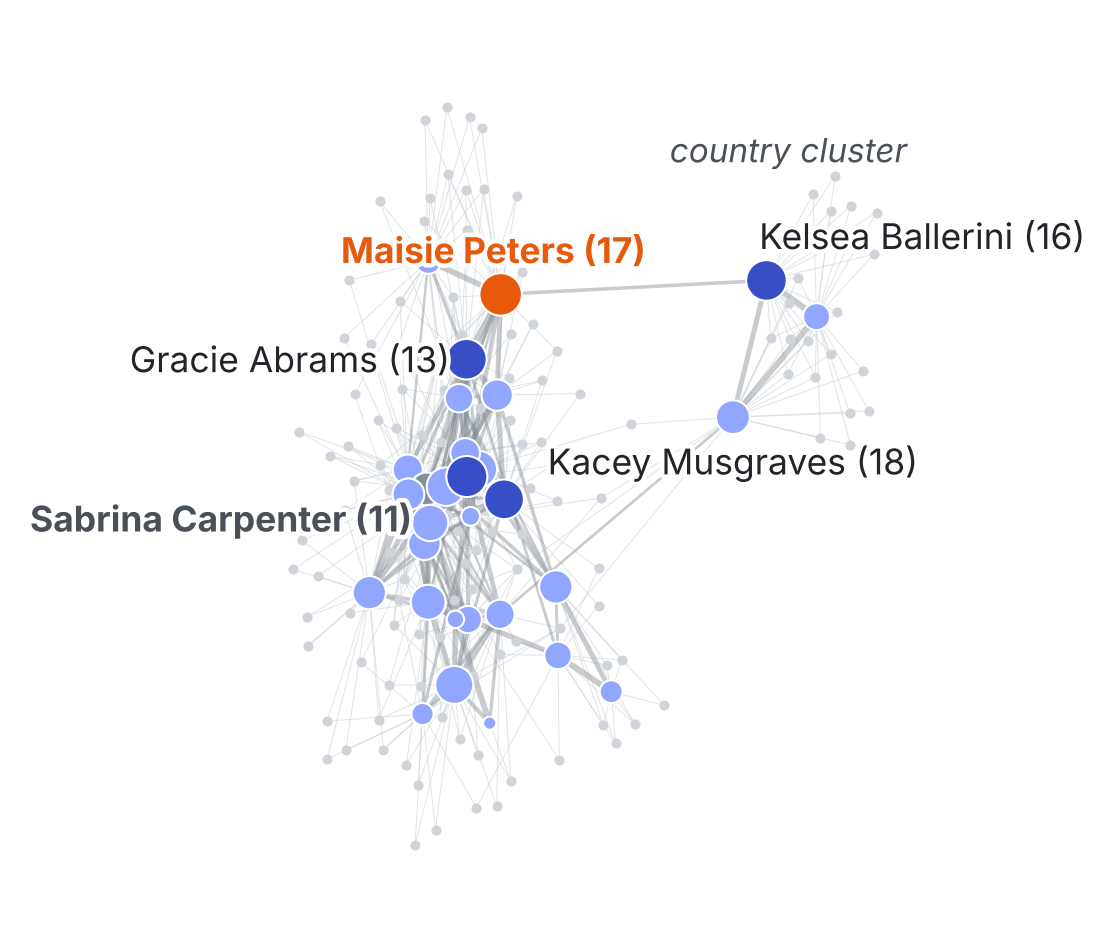

{'Maisie Peters': 17, 'Sabrina Carpenter': 11, 'Gracie Abrams': 13, 'Kelsea Ballerini': 16, 'Kacey Musgraves': 18}


In [12]:
import matplotlib.patheffects as pe
Gf = build_graph(raw, CUTOFF)
outside = {a: [n for n in Gf[a] if n not in L1] for a in cand_list if a in Gf}
core = Gf.subgraph([a for a in cand_list if a in Gf]).copy()
ORANGE, GREY, BLUE, LIGHT = "#E8590C", "#868E96", "#364FC7", "#CED4DA"
highlight = list(stab.index[:5])
pos = nx.spring_layout(Gf, weight="weight", seed=11, k=0.18, iterations=200)

fig, ax = plt.subplots(figsize=(3.4, 3.0), dpi=300)
outs = [n for n in Gf if n not in L1]
nx.draw_networkx_edges(Gf, pos, edgelist=[(u, v) for u, v in Gf.edges() if (u in L1) != (v in L1)], ax=ax, edge_color=LIGHT, width=0.25, alpha=0.6)
nx.draw_networkx_edges(core, pos, ax=ax, edge_color=GREY, width=[0.2 + 1.2 * core[u][v]["weight"] for u, v in core.edges()], alpha=0.45)
nx.draw_networkx_nodes(Gf, pos, nodelist=outs, node_size=2, node_color=LIGHT, ax=ax)
inv = {a: 31 - stab.loc[a, "mean_bridge_rank"] for a in core}
colors = [ORANGE if a == ROBUST else (GREY if a == MOST_SIM else (BLUE if a in highlight else "#91A7FF")) for a in core]
nx.draw_networkx_nodes(core, pos, node_size=[5 + 3.5 * inv[a] for a in core], node_color=colors, edgecolors="white", linewidths=0.5, ax=ax)
lab = list(dict.fromkeys([ROBUST, MOST_SIM, "Gracie Abrams", "Kelsea Ballerini", "Kacey Musgraves"]))
OFF = {"Sabrina Carpenter": (-0.04, -0.05, "right"), "Halsey": (0.05, -0.06, "left"), "Troye Sivan": (0.05, -0.06, "left"),
       "Gracie Abrams": (-0.045, 0.0, "right"), "Maisie Peters": (-0.02, 0.075, "center"), "Kelsea Ballerini": (-0.02, 0.075, "left"),
       "Miley Cyrus": (0.04, 0.0, "left"), "Kacey Musgraves": (0.0, -0.075, "center"), "Maren Morris": (0.04, -0.02, "left")}
for a in lab:
    if a not in pos: continue
    x, y = pos[a]; dx, dy, ha = OFF.get(a, (0.0, 0.05, "center"))
    t = ax.text(x + dx, y + dy, f"{a} ({len(outside.get(a, []))})", fontsize=8.5, ha=ha, va="center",
                color=ORANGE if a == ROBUST else ("#495057" if a == MOST_SIM else "#212529"),
                fontweight="bold" if a in (ROBUST, MOST_SIM) else "normal")
    t.set_path_effects([pe.withStroke(linewidth=2.2, foreground="white")])
if "Kelsea Ballerini" in pos:
    x, y = pos["Kelsea Ballerini"]
    ax.text(x + 0.06, y + 0.2, "country cluster", fontsize=8, style="italic", color="#495057", ha="center")
ax.axis("off"); plt.tight_layout(pad=0.1)
plt.savefig("fig_full_graph_key_nodes.png", bbox_inches="tight", dpi=300); plt.show()
print({a: len(outside.get(a, [])) for a in lab})

## 7c. ใครเชื่อม country cluster กับ pop core

In [13]:
COUNTRY = {a for a in cand_list if tags.get(a) and tags[a][0][0] == "country"}
Gx = nx.Graph()
for r in raw.itertuples():
    if r.source == r.target: continue
    w = max(r.match, Gx[r.source][r.target]["weight"]) if Gx.has_edge(r.source, r.target) else r.match
    Gx.add_edge(r.source, r.target, weight=w)
Gx.remove_nodes_from([n for n in list(Gx) if n.lower() == SEED.lower()])
print("Country cluster (primary tag = country):", sorted(COUNTRY))
for c in SWEEP:
    links = [(u, v, round(Gx[u][v]["weight"], 2)) for u in COUNTRY for v in Gx[u] if v in L1 and v not in COUNTRY and Gx[u][v]["weight"] >= c]
    print(f"cutoff {c}: {len(links)} link(s) country <-> other Swift-adjacent artists: {links}")

Country cluster (primary tag = country): ['Kacey Musgraves', 'Kelsea Ballerini', 'Maren Morris']
cutoff 0.2: 2 link(s) country <-> other Swift-adjacent artists: [('Kacey Musgraves', 'Miley Cyrus', 0.38), ('Kelsea Ballerini', 'Maisie Peters', 0.53)]
cutoff 0.3: 2 link(s) country <-> other Swift-adjacent artists: [('Kacey Musgraves', 'Miley Cyrus', 0.38), ('Kelsea Ballerini', 'Maisie Peters', 0.53)]
cutoff 0.4: 1 link(s) country <-> other Swift-adjacent artists: [('Kelsea Ballerini', 'Maisie Peters', 0.53)]


## 7d. Figure for the A4 page — 14 key Swift-adjacent artists
Each artist keeps its 3 strongest links among the shown artists, plus every link into the country cluster (teal). Size = bridge robustness (mean rank over 12 configs); orange = most robust bridge; grey = most similar to Swift.

Figure subgraph: 14 nodes, 24 edges


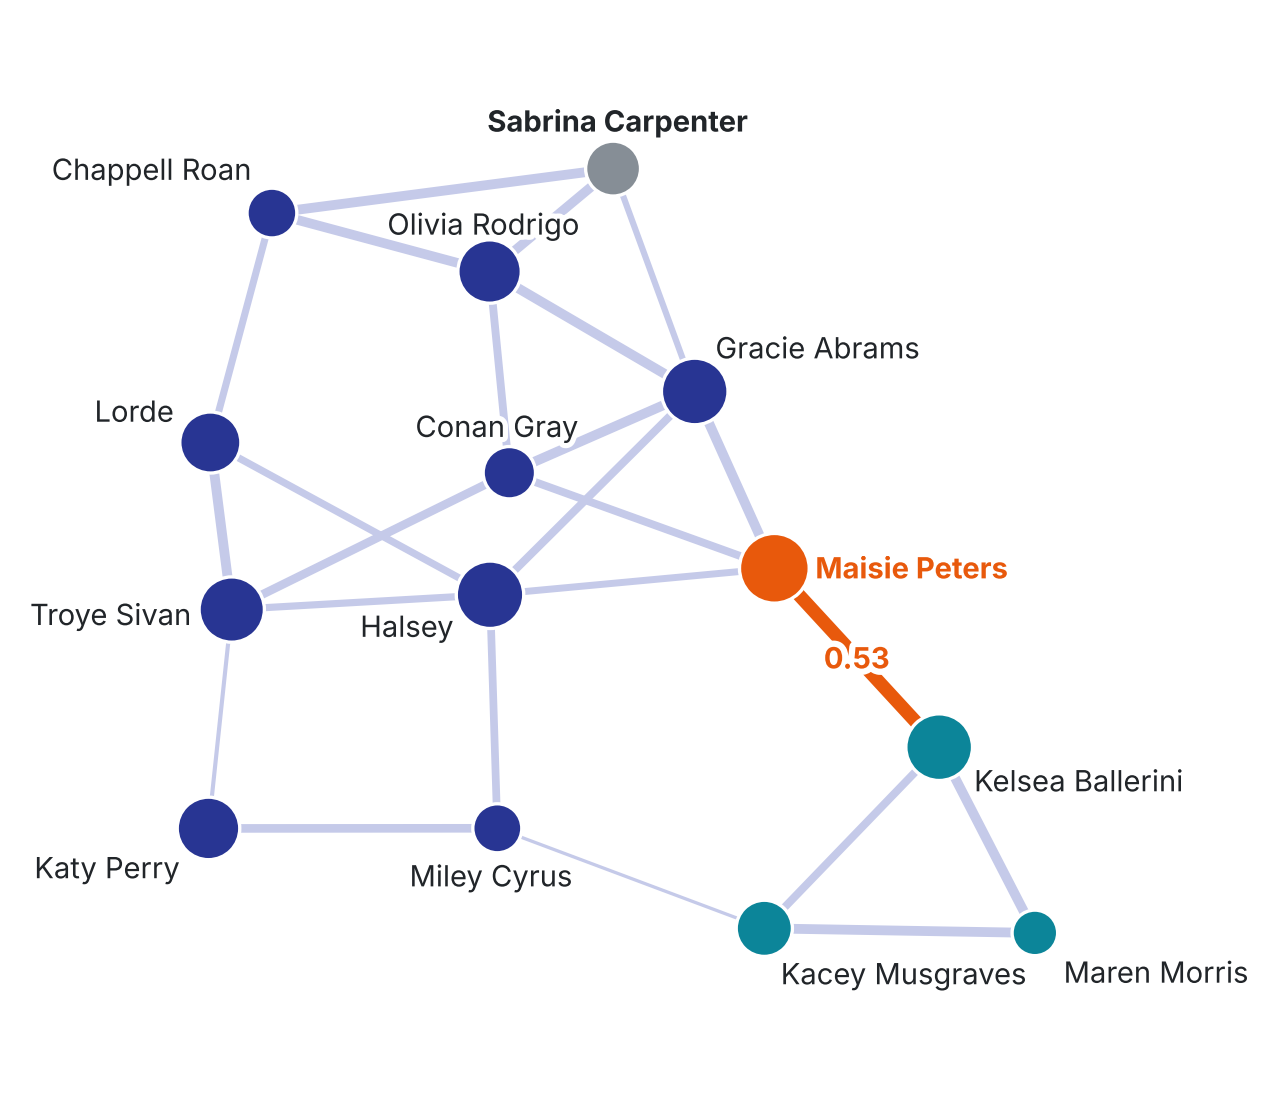

In [14]:
import networkx as nx, matplotlib.pyplot as plt, matplotlib.patheffects as pe, numpy as np
SHOW = ["Maisie Peters","Halsey","Kelsea Ballerini","Gracie Abrams","Troye Sivan","Olivia Rodrigo","Katy Perry",
        "Lorde","Sabrina Carpenter","Kacey Musgraves","Maren Morris","Miley Cyrus","Conan Gray","Chappell Roan"]
Gf = build_graph(raw, CUTOFF)
SHOW = [a for a in SHOW if a in Gf]
COUNTRY = {"Kelsea Ballerini","Kacey Musgraves","Maren Morris"}
S = nx.Graph(); S.add_nodes_from(SHOW)
full = Gf.subgraph(SHOW)
keep = set()
for a in SHOW:   # each artist's 3 strongest links among the shown artists
    for b in sorted(full[a], key=lambda b: (-full[a][b]["weight"], b))[:3]: keep.add(tuple(sorted((a, b))))
for u, v in full.edges():   # plus every link into or out of the country cluster
    if (u in COUNTRY) != (v in COUNTRY): keep.add(tuple(sorted((u, v))))
for u, v in sorted(keep): S.add_edge(u, v, weight=full[u][v]["weight"])
print(f"Figure subgraph: {S.number_of_nodes()} nodes, {S.number_of_edges()} edges")
pos = nx.kamada_kawai_layout(S, weight=None)
ORANGE, NAVY, GREY, EDGE, TEAL = "#E8590C", "#283593", "#868E96", "#C5CAE9", "#0C8599"
fig, ax = plt.subplots(figsize=(4.2, 3.5), dpi=300)
key = tuple(sorted(("Kelsea Ballerini", "Maisie Peters")))
others = [e for e in S.edges() if tuple(sorted(e)) != key]
nx.draw_networkx_edges(S, pos, edgelist=others, width=[0.6 + 2.5 * (S[u][v]["weight"] - 0.3) for u, v in others], edge_color=EDGE, ax=ax)
nx.draw_networkx_edges(S, pos, edgelist=[key], width=3.2, edge_color=ORANGE, ax=ax)
col = [ORANGE if a == ROBUST else GREY if a == MOST_SIM else TEAL if a in COUNTRY else NAVY for a in S]
size = [25 + 9 * (31 - stab.loc[a, "mean_bridge_rank"]) for a in S]
nx.draw_networkx_nodes(S, pos, node_color=col, node_size=size, edgecolors="white", linewidths=0.8, ax=ax)
c = np.mean(list(pos.values()), axis=0)
for a, (x, y) in pos.items():
    d = np.array([x, y]) - c; d = d / (np.linalg.norm(d) + 1e-9)
    ha = "left" if d[0] > 0.35 else ("right" if d[0] < -0.35 else "center")
    va = "bottom" if d[1] > 0.35 else ("top" if d[1] < -0.35 else "center")
    t = ax.text(x + 0.075 * d[0], y + 0.075 * d[1], a, fontsize=7, ha=ha, va=va,
                color=ORANGE if a == ROBUST else "#212529", fontweight="bold" if a in (ROBUST, MOST_SIM) else "normal")
    t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="white")])
(x1, y1), (x2, y2) = pos[key[0]], pos[key[1]]
t = ax.text((x1 + x2) / 2, (y1 + y2) / 2, f"{S[key[0]][key[1]]['weight']:.2f}", fontsize=7, color=ORANGE, fontweight="bold", ha="center", va="center")
t.set_path_effects([pe.withStroke(linewidth=3, foreground="white")])
ax.margins(0.12); ax.axis("off"); plt.tight_layout(pad=0.1)
plt.savefig("fig_a4_network.png", dpi=300, bbox_inches="tight"); plt.show()


## 8. ตัวเลขสำหรับหน้า A4

In [15]:
summary = {
  "Source": "Last.fm API artist.getSimilar + artist.getTopTags",
  "Fetched at": FETCHED_AT,
  "Raw records (similarity pairs)": len(raw),
  "Unique artists before pruning": int(pd.unique(raw[['source','target']].values.ravel()).size),
  "Final nodes / edges (cutoff %.2f)" % CUTOFF: f"{G.number_of_nodes()} / {G.number_of_edges()}",
  "Seed excluded": SEED,
  "Most similar to Swift": f"{top_sim.artist} (sim {top_sim.swift_similarity:.2f}, btw {top_sim.betweenness:.3f})",
  "#1 bridge": f"{top_btw.artist} (sim {top_btw.swift_similarity:.2f}, btw {top_btw.betweenness:.3f}, {top_btw.new_reach} neighbours outside Swift circle)",
  "Spearman sim vs btw": round(rho, 2),
  "Cutoff sweep #1 bridge": " / ".join(f"{c}: {tops[c][0] if tops[c] else '-'}" for c in SWEEP),
  "Tag-graph top-5 overlap": f"{len(set(alt_top) & base)}/{TOP_N}",
  "Tag-graph top-5": ", ".join(alt_top),
  "Most robust bridge (12 configs)": f"{ROBUST}: mean rank {stab.loc[ROBUST,'mean_bridge_rank']:.1f}, top-5 in {stab.loc[ROBUST,'top5_in']}/{N_CFG}, top-3 in {stab.loc[ROBUST,'top3_in']}/{N_CFG}, sim {swift_sim[ROBUST]:.2f} (rank {stab.loc[ROBUST,'sim_rank']})",
  "Most similar artist across 12 configs": f"{MOST_SIM}: mean rank {stab.loc[MOST_SIM,'mean_bridge_rank']:.1f}, top-5 in {stab.loc[MOST_SIM,'top5_in']}/{N_CFG}, best rank {stab.loc[MOST_SIM,'best_rank']}",
}
pd.Series(summary).to_frame("value").to_csv("summary_for_A4.csv")
pd.Series(summary).to_frame("value")

,value
Source,Last.fm API artist.getSimilar + artist.getTopTags
Fetched at,2026-10-16T10:46
Raw records (similarity pairs),929
Unique artists before pruning,337
Final nodes / edges (cutoff 0.30),158 / 520
Seed excluded,Taylor Swift
Most similar to Swift,"Sabrina Carpenter (sim 1.00, btw 0.124)"
#1 bridge,"Gracie Abrams (sim 0.91, btw 0.521, 13 neighbo..."
Spearman sim vs btw,0.52
Cutoff sweep #1 bridge,0.2: Gracie Abrams / 0.3: Gracie Abrams / 0.4:...
